In [1]:
# Parts: reproducibilno treniranje U-Net segmentacije (MobileNetV3Small)
# Konfiguracija — mijenjaj SEEDS / SEG_PARTS_TO_USE po potrebi.
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
os.environ["TF_XLA_FLAGS"] = ""
os.environ["XLA_FLAGS"] = "--xla_gpu_cuda_data_dir=."

import sys, json, random, time, gc, subprocess, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt

SEEDS = [42, 123, 2024, 7, 13]
SEED = 42                         # default / seed za pojedinačno pokretanje
SEG_PARTS_TO_USE = ["pupil", "iris", "lid"]
ALLOWED_PARTS = {"pupil", "iris", "lid"}
OUTPUT_BASE = Path("/home/fipulab/anastazija/runs/seg_only")
BATCH_SIZE = 128
USE_MIXED_PRECISION = True  # Ako se AutoCastVariable/XLA greška ponovi, postavi False.
IMAGE_SHAPE = (128, 128, 3)
MASK_SHAPE = (128, 128, 1)
PHASE1_EPOCHS = 6
PHASE2_EPOCHS = 60
VAL_STEPS_LIMIT = 200
NUM_PARALLEL_CALLS = 4
AUTOTUNE = tf.data.AUTOTUNE

# Putanje dataset-a
BASE_PATH = Path("/home/fipulab/anastazija/TEyeD_preprocessed")
DATASET_FOLDER = "128x128_stride10_q4_seg_pupil-iris-lid_2D"
PREPROCESSED_ROOT = BASE_PATH / DATASET_FOLDER
SPLIT_ROOTS = {s: PREPROCESSED_ROOT / s for s in ("train", "val", "test")}

# Provjera metapodataka iz Preprocessed.ipynb (upozorenje, ne prekida rad).
metadata_path = PREPROCESSED_ROOT.parent / "metadata.json"
if not metadata_path.exists():
    warnings.warn(f"Nedostaje metadata.json: {metadata_path}; nastavljam bez njega.")

# Threading se postavlja prije kreiranja dataset/model operacija.
tf.config.threading.set_inter_op_parallelism_threads(4)
tf.config.threading.set_intra_op_parallelism_threads(4)
gpus = tf.config.list_physical_devices("GPU")
if gpus:
    for gpu in gpus:
        try:
            tf.config.experimental.set_memory_growth(gpu, True)
        except RuntimeError as exc:
            warnings.warn(f"Memory growth nije moguće postaviti (TF je možda već inicijaliziran): {exc}")
    try:
        if USE_MIXED_PRECISION:
            tf.keras.mixed_precision.set_global_policy("mixed_float16")
            print("Mixed precision uključen (mixed_float16); XLA na optimizeru je isključen.")
        else:
            tf.keras.mixed_precision.set_global_policy("float32")
            print("Mixed precision ručno isključen; koristi se float32.")
    except Exception as exc:
        warnings.warn(f"Mixed precision nije dostupan: {exc}")
else:
    tf.keras.mixed_precision.set_global_policy("float32")
    warnings.warn("GPU nije dostupan; mixed precision je preskočen, treniranje će koristiti CPU.")

def gpu_memory_report():
    if not gpus:
        print("GPU memorija: nije dostupna (CPU način rada).")
        return None
    try:
        out = subprocess.check_output(
            ["nvidia-smi", "--query-gpu=memory.total,memory.used,memory.free", "--format=csv,noheader,nounits"],
            text=True
        ).strip().splitlines()
        free_gb = []
        for i, line in enumerate(out):
            total, used, free = [float(x.strip()) for x in line.split(",")]
            free_gb.append(free / 1024.0)
            print(f"GPU {i}: ukupno {total/1024:.2f} GB, zauzeto {used/1024:.2f} GB, slobodno {free/1024:.2f} GB")
        if min(free_gb) < 6:
            warnings.warn("Slobodna GPU memorija je ispod 6 GB. Parts učitava RGB + tri maske; razmotri manji batch.")
        return min(free_gb)
    except Exception as exc:
        warnings.warn(f"Nije moguće očitati GPU memoriju preko nvidia-smi: {exc}")
        return None

gpu_memory_report()

# Učitavanje i validacija CSV-ova. subject_id/video_id su obavezni metapodaci.
SPLIT_DF = {}
for split, root in SPLIT_ROOTS.items():
    csv_path = root / "labels.csv"
    if not csv_path.exists():
        raise FileNotFoundError(f"Nedostaje {csv_path}. Prvo pokreni predobradu.")
    df = pd.read_csv(csv_path)
    required = {"filename", "subject_id", "video_id",
                "mask_valid_pupil", "mask_valid_iris", "mask_valid_lid"}
    missing = required - set(df.columns)
    if missing:
        raise ValueError(f"{csv_path}: nedostaju obavezni stupci {sorted(missing)}")
    SPLIT_DF[split] = df
    print(f"{split}: {len(df):,} uzoraka, {df['video_id'].nunique():,} videa, "
          f"{df['subject_id'].nunique():,} ispitanika")

for part in ("pupil", "iris", "lid"):
    for split, root in SPLIT_ROOTS.items():
        mask_dir = root / f"seg_{part}_2D"
        if not mask_dir.is_dir():
            raise FileNotFoundError(f"Nedostaje mapa maski: {mask_dir}")
print("Provjera mapa maski: OK.")


INFO:tensorflow:Mixed precision compatibility check (mixed_float16): OK
Your GPU will likely run quickly with dtype policy mixed_float16 as it has compute capability of at least 7.0. Your GPU: NVIDIA GeForce RTX 3090, compute capability 8.6
Mixed precision uključen (mixed_float16); XLA na optimizeru je isključen.
GPU 0: ukupno 23.70 GB, zauzeto 0.02 GB, slobodno 23.68 GB
train: 339,466 uzoraka, 264 videa, 76 ispitanika
val: 135,958 uzoraka, 108 videa, 22 ispitanika
test: 79,964 uzoraka, 50 videa, 11 ispitanika
Provjera mapa maski: OK.


In [2]:
# Validacija konfiguracije i tf.data loader koji učitava slike/masku lijeno po uzorku.
def validate_parts(parts):
    if not isinstance(parts, (list, tuple)) or not parts:
        raise ValueError("SEG_PARTS_TO_USE mora biti neprazna lista.")
    invalid = set(parts) - ALLOWED_PARTS
    if invalid:
        raise ValueError(f"Nepoznati dijelovi {sorted(invalid)}; dopušteno: {sorted(ALLOWED_PARTS)}")
    if len(set(parts)) != len(parts):
        raise ValueError("SEG_PARTS_TO_USE ne smije sadržavati duplikate.")
    return list(parts)

def set_all_seeds(seed):
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
    tf.keras.utils.set_random_seed(seed)

PART_ORDER = ["pupil", "iris", "lid"]
CHANNEL_INDEX = {p: i for i, p in enumerate(PART_ORDER)}

def make_dataset(df, split_root, batch_size, training=False, seed=42):
    # y_true ima 6 kanala: prva 3 su maske, zadnja 3 su mask_valid
    # (validnost je broadcastana prostorno), pa custom loss ignorira nedostupne maske.
    records = df[["filename", "mask_valid_pupil", "mask_valid_iris", "mask_valid_lid"]].copy()
    filenames = records["filename"].astype(str).to_numpy()
    valid = records[["mask_valid_pupil", "mask_valid_iris", "mask_valid_lid"]].fillna(0).to_numpy(np.float32)
    ds = tf.data.Dataset.from_tensor_slices((filenames, valid))
    if training:
        ds = ds.shuffle(min(len(records), 20000), seed=seed, reshuffle_each_iteration=True)

    root_str = str(split_root)
    def _load(filename, valid_flags):
        image_path = tf.strings.join([root_str, "/", filename])
        image = tf.io.decode_jpeg(tf.io.read_file(image_path), channels=3)
        image = tf.image.resize(image, IMAGE_SHAPE[:2], method="bilinear")
        image = tf.cast(image, tf.float32) / 127.5 - 1.0

        # filename = <video_id>/<frame>.jpg; mask je <split>/seg_<part>_2D/<video_id>/<frame>.png
        pieces = tf.strings.split(filename, "/")
        video = pieces[-2]
        frame = tf.strings.regex_replace(pieces[-1], r"\.jpg$", ".png")
        masks = []
        for part in PART_ORDER:
            mask_path = tf.strings.join([root_str, "/seg_", part, "_2D/", video, "/", frame])
            mask = tf.io.decode_png(tf.io.read_file(mask_path), channels=1)
            mask = tf.image.resize(mask, MASK_SHAPE[:2], method="nearest")
            mask = tf.cast(mask > 0, tf.float32)
            masks.append(mask)
        masks = tf.concat(masks, axis=-1)
        valid_map = tf.ones_like(masks) * tf.reshape(valid_flags, (1, 1, 3))
        target = tf.concat([masks, valid_map], axis=-1)
        image.set_shape((128, 128, 3))
        target.set_shape((128, 128, 6))
        return image, target

    ds = ds.map(_load, num_parallel_calls=NUM_PARALLEL_CALLS, deterministic=not training)
    ds = ds.batch(batch_size, drop_remainder=False)
    return ds.prefetch(AUTOTUNE)

def active_channel_indices(parts):
    return [CHANNEL_INDEX[p] for p in parts]

def make_masked_bce(parts):
    active = tf.constant(active_channel_indices(parts), dtype=tf.int32)
    bce = keras.losses.BinaryCrossentropy(reduction="none")
    def masked_bce(y_true, y_pred):
        masks = tf.gather(y_true[..., :3], active, axis=-1)
        valid = tf.gather(y_true[..., 3:6], active, axis=-1)
        pred = tf.gather(tf.cast(y_pred, tf.float32), active, axis=-1)
        per_pixel = keras.backend.binary_crossentropy(masks, pred)
        weighted = per_pixel * valid
        return tf.reduce_sum(weighted) / tf.maximum(tf.reduce_sum(valid), 1.0)
    masked_bce.__name__ = "masked_bce"
    return masked_bce

def make_part_iou(part):
    idx = CHANNEL_INDEX[part]
    def metric(y_true, y_pred):
        truth = y_true[..., idx]
        valid = y_true[..., idx + 3]
        pred = tf.cast(y_pred[..., idx], tf.float32) >= 0.5
        truth = truth >= 0.5
        valid = valid > 0.5
        pred = tf.logical_and(pred, valid)
        truth = tf.logical_and(truth, valid)
        intersection = tf.reduce_sum(tf.cast(tf.logical_and(pred, truth), tf.float32))
        union = tf.reduce_sum(tf.cast(tf.logical_or(pred, truth), tf.float32))
        return tf.math.divide_no_nan(intersection, union)
    metric.__name__ = f"iou_{part}"
    return metric

def make_train_val_datasets(batch_size, seed, parts):
    train_ds = make_dataset(SPLIT_DF["train"], SPLIT_ROOTS["train"], batch_size, True, seed)
    val_ds_full = make_dataset(SPLIT_DF["val"], SPLIT_ROOTS["val"], batch_size, False, seed)
    # Ograničenje od 200 batch-eva zadržano kao sigurnosna mjera zbog memorijskog limita.
    val_ds = val_ds_full.take(VAL_STEPS_LIMIT)
    return train_ds, val_ds, val_ds_full

parts = validate_parts(SEG_PARTS_TO_USE)
print("Aktivni dijelovi za loss:", parts)


Aktivni dijelovi za loss: ['pupil', 'iris', 'lid']


In [3]:
# Ista arhitektura: MobileNetV3Small + U-Net dekoder sa skip vezama.
# Izlaz je uvijek 3 kanala (pupil, iris, lid); ablacija mijenja isključivo loss.
def get_parts_unet_model():
    inputs = keras.Input(shape=(128, 128, 3), name="image_input")
    base = keras.applications.MobileNetV3Small(
        input_shape=(128, 128, 3), include_top=False, weights="imagenet",
        include_preprocessing=False, alpha=1.0
    )
    skip1_tensor = base.get_layer("expanded_conv/project/BatchNorm").output
    skip2_tensor = base.get_layer("expanded_conv_2/project/BatchNorm").output
    feature_extractor = keras.Model(
        inputs=base.input, outputs=[skip1_tensor, skip2_tensor, base.output],
        name="feature_extractor"
    )
    skip1, skip2, bottleneck = feature_extractor(inputs)

    x = layers.Conv2DTranspose(96, 3, strides=2, padding="same", activation="relu")(bottleneck)
    x = layers.Resizing(int(skip2.shape[1]), int(skip2.shape[2]))(x)
    x = layers.Concatenate()([x, skip2])
    x = layers.Conv2D(96, 3, padding="same", activation="relu")(x)

    x = layers.Conv2DTranspose(48, 3, strides=2, padding="same", activation="relu")(x)
    x = layers.Resizing(int(skip1.shape[1]), int(skip1.shape[2]))(x)
    x = layers.Concatenate()([x, skip1])
    x = layers.Conv2D(48, 3, padding="same", activation="relu")(x)

    x = layers.Conv2DTranspose(24, 3, strides=2, padding="same", activation="relu")(x)
    x = layers.Conv2D(24, 3, padding="same", activation="relu")(x)
    x = layers.Conv2DTranspose(12, 3, strides=2, padding="same", activation="relu")(x)
    x = layers.Resizing(128, 128)(x)

    # float32 izlaz radi numeričke stabilnosti uz mixed_float16.
    seg_output = layers.Conv2D(3, 1, activation="sigmoid", dtype="float32", name="seg")(x)
    model = keras.Model(inputs=inputs, outputs=seg_output, name="MobileNetV3_UNet_Parts")
    return model, base

def _make_optimizer_without_xla(optimizer_cls, **kwargs):
    """
    TF/Keras 2.11 može interno XLA-kompilirati optimizer.apply_gradients
    čak i kada je model.compile(jit_compile=False). Isključujemo XLA i na
    samom optimizeru kako bi mixed_float16 AutoCastVariable radile ispravno.
    """
    try:
        return optimizer_cls(jit_compile=False, **kwargs)
    except TypeError:
        # Kompatibilnost sa starijim Keras verzijama koje nemaju javni argument.
        opt = optimizer_cls(**kwargs)
        try:
            opt.jit_compile = False
        except Exception:
            try:
                opt._jit_compile = False
            except Exception:
                warnings.warn(
                    "Ova Keras verzija ne dopušta isključivanje XLA na optimizeru. "
                    "Ako se AutoCastVariable greška ponovi, postavi USE_MIXED_PRECISION=False."
                )
        return opt

def compile_parts_model(model, parts, phase=1):
    if phase == 1:
        optimizer = _make_optimizer_without_xla(
            keras.optimizers.Adam, learning_rate=1e-3
        )
    else:
        AdamW = getattr(keras.optimizers, "AdamW", None)
        if AdamW is None:
            AdamW = tf.keras.optimizers.experimental.AdamW
        optimizer = _make_optimizer_without_xla(
            AdamW, learning_rate=1e-4, weight_decay=1e-3
        )
    model.compile(
        optimizer=optimizer,
        loss=make_masked_bce(parts),
        metrics=[make_part_iou(p) for p in PART_ORDER],
        jit_compile=False,
        run_eagerly=False
    )


In [4]:
# Treniranje seedova, evaluacija po uzorku/ispitaniku i spremanje artefakata.
class EpochTimer(keras.callbacks.Callback):
    def __init__(self, total_epochs=PHASE1_EPOCHS + PHASE2_EPOCHS):
        super().__init__(); self.epoch_started = None; self.durations = []; self.total_epochs = total_epochs
    def on_epoch_begin(self, epoch, logs=None): self.epoch_started = time.time()
    def on_epoch_end(self, epoch, logs=None):
        duration = time.time() - self.epoch_started; self.durations.append(duration)
        avg = float(np.mean(self.durations)); remaining = max(0, self.total_epochs - (epoch + 1))
        print(f"Procjena vremena po epohi: {avg/60:.1f} min; preostalo približno {remaining*avg/3600:.2f} h")

def build_callbacks(output_dir):
    # Težine se spremaju bez optimizer state-a: izbjegava LossScaleOptimizerV3.variables
    # problem pri serijalizaciji mixed-precision optimizatora.
    return [
        keras.callbacks.ModelCheckpoint(
            filepath=str(output_dir / "best_parts.weights.h5"),
            monitor="val_loss", mode="min", save_best_only=True,
            save_weights_only=True, verbose=1
        ),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2,
            mode="min", verbose=1, min_lr=1e-6),
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, mode="min",
            restore_best_weights=True, verbose=1)
    ]

def combine_histories(h1, h2):
    d1, d2 = pd.DataFrame(h1.history), pd.DataFrame(h2.history)
    if len(d1) and len(d2): return pd.concat([d1, d2], ignore_index=True)
    return d1 if len(d1) else d2

def save_training_plots(history_df, output_dir):
    if history_df.empty: return
    epochs = np.arange(1, len(history_df) + 1)
    for key, title, ylabel, filename in [
        ("loss", "Segmentation Loss", "Loss", "fig_parts_loss.png"),
        ("iou_pupil", "IoU — pupil", "IoU", "fig_parts_iou_pupil.png"),
        ("iou_iris", "IoU — iris", "IoU", "fig_parts_iou_iris.png"),
        ("iou_lid", "IoU — lid", "IoU", "fig_parts_iou_lid.png")]:
        val_key = "val_" + key
        if key not in history_df or val_key not in history_df: continue
        plt.figure(figsize=(8, 5), dpi=200)
        plt.plot(epochs, history_df[key], label=f"Train {ylabel}", linewidth=2)
        plt.plot(epochs, history_df[val_key], label=f"Val {ylabel}", linewidth=2)
        if len(history_df) > PHASE1_EPOCHS:
            plt.axvline(x=PHASE1_EPOCHS, linestyle="--", label="Full fine-tuning starts")
        plt.xlabel("Epoch"); plt.ylabel(ylabel); plt.title(title); plt.legend()
        plt.grid(True, linestyle=":", alpha=0.5); plt.tight_layout()
        plt.savefig(output_dir / filename, dpi=200, bbox_inches="tight"); plt.close()

def _find_z_column(df):
    for c in ("z", "gaze_z", "gaze_3d_z", "gaze_vector_z", "gaze_z_3d"):
        if c in df.columns: return c
    return None

def evaluate_per_part(model, df, split_root, batch_size, output_dir=None, seed=None, config=None):
    """Vraća globalni IoU i IoU po uzorku; z<=0 se označava valid_gaze=0 i izuzima iz agregata."""
    ds = make_dataset(df, split_root, batch_size, False)
    sums = {p: 0.0 for p in PART_ORDER}; counts = {p: 0 for p in PART_ORDER}
    subject_sums = {}; subject_counts = {}; subject_valid_samples = {}; rows = []
    z_col = _find_z_column(df)
    if z_col is None:
        warnings.warn("Nema z stupca u labels.csv; valid_gaze će uvijek biti 1.")
    offset = 0
    for images, target in ds:
        pred = model(images, training=False).numpy(); truth = target.numpy()
        batch_n = len(pred); batch_meta = df.iloc[offset:offset + batch_n]
        assert batch_n == len(batch_meta), (
            f"Nekonzistentan batch u evaluaciji: batch_n={batch_n}, "
            f"len(batch_meta)={len(batch_meta)}, offset={offset}"
        )
        offset += batch_n
        for b in range(batch_n):
            meta = batch_meta.iloc[b]
            z_value = pd.to_numeric(meta[z_col], errors="coerce") if z_col else np.nan
            valid_gaze = int(not (z_col and pd.notna(z_value) and float(z_value) <= 0))
            subject = str(meta.get("subject_id", "unknown"))
            row = {"subject_id": subject, "video_id": str(meta.get("video_id", "")),
                   "filename": str(meta.get("filename", "")), "valid_gaze": valid_gaze}
            sample_ious = []
            sample_has_valid_mask = False
            for part in PART_ORDER:
                i = CHANNEL_INDEX[part]; valid = truth[b, ..., i + 3] > 0.5
                if not valid_gaze or not np.any(valid):
                    iou = np.nan
                else:
                    sample_has_valid_mask = True
                    t = (truth[b, ..., i] >= 0.5) & valid
                    q = (pred[b, ..., i] >= 0.5) & valid
                    union = np.logical_or(t, q).sum()
                    iou = float(np.logical_and(t, q).sum() / union) if union else 1.0
                    sums[part] += iou; counts[part] += 1
                    sample_ious.append(iou)
                    subject_sums.setdefault(subject, {p: 0.0 for p in PART_ORDER})[part] += iou
                    subject_counts.setdefault(subject, {p: 0 for p in PART_ORDER})[part] += 1
                row[f"iou_{part}"] = iou
            if valid_gaze == 1 and sample_has_valid_mask:
                subject_valid_samples[subject] = subject_valid_samples.get(subject, 0) + 1
            row["mean_iou"] = float(np.nanmean(sample_ious)) if sample_ious else np.nan
            rows.append(row)
    global_iou = {p: (sums[p] / counts[p] if counts[p] else None) for p in PART_ORDER}
    per_subject = {}
    for subject in sorted(subject_sums):
        per_subject[subject] = {p: (subject_sums[subject][p] / subject_counts[subject][p]
            if subject_counts[subject][p] else None) for p in PART_ORDER}
        per_subject[subject]["n_samples"] = int(subject_valid_samples.get(subject, 0))
    pred_df = pd.DataFrame(rows, columns=["subject_id", "video_id", "filename", "iou_pupil",
        "iou_iris", "iou_lid", "mean_iou", "valid_gaze"])
    if output_dir is not None:
        pred_df.to_csv(Path(output_dir) / "test_predictions.csv", index=False)
        summary = {"seed": int(seed) if seed is not None else None, "config": config or {},
                   "global_iou": global_iou, "per_subject_iou": per_subject,
                   "num_subjects": int(pred_df.loc[pred_df.valid_gaze == 1, "subject_id"].nunique())}
        (Path(output_dir) / "summary.json").write_text(json.dumps(summary, indent=2, allow_nan=False), encoding="utf-8")
    return global_iou, pred_df, per_subject

def save_inference_model(model, model_path):
    # Kloniraj već izgrađenu arhitekturu; ne inicijaliziraj ponovno MobileNetV3Small/ImageNet.
    inference_model = keras.models.clone_model(model)
    inference_model.set_weights(model.get_weights())
    inference_model.save(model_path)
    del inference_model

def run_one_seed(seed):
    seed = int(seed); set_all_seeds(seed)
    output_dir = OUTPUT_BASE / f"seed_{seed}"; output_dir.mkdir(parents=True, exist_ok=True)
    model_path = output_dir / "best_parts.keras"
    weights_path = output_dir / "best_parts.weights.h5"
    parts = validate_parts(SEG_PARTS_TO_USE)
    config = {"SEED": seed, "SEG_PARTS_TO_USE": parts, "BATCH_SIZE": BATCH_SIZE,
        "PHASE1_EPOCHS": PHASE1_EPOCHS, "PHASE2_EPOCHS": PHASE2_EPOCHS,
        "VAL_STEPS_LIMIT": VAL_STEPS_LIMIT, "IMAGE_SHAPE": list(IMAGE_SHAPE),
        "architecture": "MobileNetV3Small + U-Net decoder with skip connections",
        "optimizer_phase1": "Adam(lr=1e-3, XLA off)",
        "optimizer_phase2": "AdamW(lr=1e-4, weight_decay=1e-3, XLA off)",
        "mixed_precision": bool(USE_MIXED_PRECISION), "started_at": time.strftime("%Y-%m-%d %H:%M:%S")}

    # Samo gotov .keras model znači da je seed dovršen. Sama weights datoteka
    # može biti checkpoint usred treniranja i ne smije preskočiti evaluaciju.
    if model_path.exists() and (output_dir / "summary.json").exists():
        print(f"seed {seed}: pronađen dovršen model i summary; preskačem treniranje i ponavljam evaluaciju.")
        model = keras.models.load_model(model_path, compile=False)
        history_path = output_dir / "history.csv"
        history_df = pd.read_csv(history_path) if history_path.exists() else pd.DataFrame()
        config_path = output_dir / "config.json"
        if config_path.exists():
            try: config.update(json.loads(config_path.read_text(encoding="utf-8")))
            except Exception: pass
        test_scores, _, _ = evaluate_per_part(model, SPLIT_DF["test"], SPLIT_ROOTS["test"], 16,
            output_dir, seed, config)
    else:
        started = time.time(); batch_size = BATCH_SIZE; last_error = None
        history_df = pd.DataFrame(); model = None
        while batch_size >= 16:
            try:
                gc.collect(); tf.keras.backend.clear_session(); set_all_seeds(seed)
                train_ds, val_ds, _ = make_train_val_datasets(batch_size, seed, parts)
                model, base = get_parts_unet_model()
                # Postojeći weights checkpoint koristi se kao početna točka, ali faze se ponovno izvode.
                if weights_path.exists():
                    print(f"seed {seed}: pokušavam učitati postojeće težine kao checkpoint početnu točku.")
                    try:
                        model.load_weights(weights_path)
                    except Exception as exc:
                        # Nekompatibilan HDF5 checkpoint ne smije zaustaviti seed.
                        warnings.warn(
                            f"Checkpoint {weights_path.name} nije kompatibilan ({type(exc).__name__}: {exc}). "
                            "Sačuvat ću ga kao backup i pokrenuti seed od početka."
                        )
                        backup_path = weights_path.with_name(weights_path.name + ".incompatible")
                        if backup_path.exists():
                            backup_path = weights_path.with_name(
                                weights_path.name + f".incompatible_{int(time.time())}"
                            )
                        weights_path.rename(backup_path)
                        print(f"Nekompatibilne težine sačuvane su u: {backup_path.name}")
                elif model_path.exists():
                    # Kompatibilnost s ranijim pokretanjem koje je spremilo .keras
                    # nakon prve faze, ali nije dovršilo evaluaciju/summary.
                    print(f"seed {seed}: učitavam postojeći .keras checkpoint kao početne težine.")
                    old_model = keras.models.load_model(model_path, compile=False)
                    model.set_weights(old_model.get_weights())
                    del old_model
                callbacks = build_callbacks(output_dir) + [EpochTimer()]
                base.trainable = False; compile_parts_model(model, parts, phase=1)
                print(f"=== seed {seed}: faza 1, batch={batch_size} ===")
                h1 = model.fit(train_ds, validation_data=val_ds, validation_steps=VAL_STEPS_LIMIT,
                    epochs=PHASE1_EPOCHS, callbacks=callbacks, verbose=1)
                base.trainable = True
                for layer in base.layers:
                    if isinstance(layer, keras.layers.BatchNormalization): layer.trainable = False
                compile_parts_model(model, parts, phase=2)
                print(f"=== seed {seed}: faza 2, batch={batch_size} ===")
                h2 = model.fit(train_ds, validation_data=val_ds, validation_steps=VAL_STEPS_LIMIT,
                    epochs=PHASE1_EPOCHS + PHASE2_EPOCHS,
                    initial_epoch=PHASE1_EPOCHS, callbacks=callbacks, verbose=1)
                history_df = combine_histories(h1, h2)
                history_df.to_csv(output_dir / "history.csv", index=False)
                training_seconds = time.time() - started
                config.update({"BATCH_SIZE_USED": batch_size, "training_seconds": training_seconds,
                    "finished_at": time.strftime("%Y-%m-%d %H:%M:%S"),
                    "epochs_completed": len(history_df),
                    "estimated_seconds_per_epoch": training_seconds / max(len(history_df), 1)})
                if training_seconds > 12 * 3600:
                    warnings.warn(f"Seed {seed} trajao je više od 12 sati; razmotri manje epoha ili batch size.")
                # EarlyStopping(restore_best_weights=True) već je vratio najbolje
                # težine u memorijski model. Ne učitavaj ih ponovno iz HDF5-a:
                # u nekim TF/Keras verzijama to uzrokuje "axes don't match array".
                # Fallback spremanja koristi trenutni model ako callback nije zapisao datoteku.
                if not weights_path.exists():
                    model.save_weights(weights_path)
                save_inference_model(model, model_path)
                test_scores, _, _ = evaluate_per_part(model, SPLIT_DF["test"], SPLIT_ROOTS["test"],
                    min(batch_size, 16), output_dir, seed, config)
                break
            except tf.errors.ResourceExhaustedError as exc:
                last_error = exc; warnings.warn(f"OOM pri batch_size={batch_size}; pokušavam manji batch.")
                batch_size //= 2; gc.collect(); tf.keras.backend.clear_session()
            except KeyboardInterrupt:
                print(f"Prekinuto korisnikom tijekom seeda {seed}; checkpoint težina ostaje sačuvan."); raise
        else:
            raise RuntimeError(f"Seed {seed} nije uspio ni s batch_size=16. Zadnja greška: {last_error}")

    config["test_iou_by_part"] = test_scores
    config["finished_at"] = time.strftime("%Y-%m-%d %H:%M:%S")
    (output_dir / "config.json").write_text(json.dumps(config, indent=2, allow_nan=False), encoding="utf-8")
    if not history_df.empty: save_training_plots(history_df, output_dir)
    best_epoch = None
    if "val_loss" in history_df and history_df["val_loss"].notna().any():
        best_epoch = int(history_df["val_loss"].idxmin() + 1)
    summary_lines = [f"Seed: {seed}", f"Model: {model_path}", f"Best epoch (val_loss): {best_epoch}"]
    for part in PART_ORDER:
        val_key = f"val_iou_{part}"
        val_score = history_df[val_key].dropna().iloc[-1] if val_key in history_df and history_df[val_key].notna().any() else None
        summary_lines += [f"final_val_iou_{part}: {val_score}", f"test_iou_{part}: {test_scores.get(part)}"]
    summary_lines.append(f"Training seconds: {config.get('training_seconds')}")
    (output_dir / "summary.txt").write_text("\n".join(summary_lines), encoding="utf-8")
    print(f"\nSeed {seed} — model: {model_path}")
    for part in PART_ORDER: print(f"  test IoU {part}: {test_scores.get(part)}")
    print(f"Ukupno vrijeme treniranja: {config.get('training_seconds', 'nije zabilježeno')} s")
    return model, history_df

# Izvrši svih pet seedova; greška jednog ne zaustavlja ostale.
seed_models, seed_histories, seed_errors = {}, {}, {}
for current_seed in SEEDS:
    try:
        m, h = run_one_seed(current_seed)
        seed_models[current_seed] = True; seed_histories[current_seed] = h
        del m; tf.keras.backend.clear_session(); gc.collect()
    except KeyboardInterrupt:
        print("Prekid zatražen; petlja je zaustavljena. Checkpoint težina ostaje spremljen."); break
    except Exception as exc:
        seed_errors[current_seed] = repr(exc)
        print(f"GREŠKA za seed {current_seed}: {type(exc).__name__}: {exc}")
        import traceback; traceback.print_exc()
        continue
if seed_errors: print("Seedovi s greškom:", seed_errors)


=== seed 42: faza 1, batch=128 ===
Epoch 1/6
2653/2653 [==============================] - ETA: 0s - loss: 0.0203 - iou_pupil: 0.8924 - iou_iris: 0.9381 - iou_lid: 0.9492
Epoch 1: val_loss improved from inf to 0.02760, saving model to /home/fipulab/anastazija/runs/seg_only/seed_42/best_parts.weights.h5
Procjena vremena po epohi: 2.1 min; preostalo približno 2.33 h
2653/2653 [==============================] - 129s 47ms/step - loss: 0.0203 - iou_pupil: 0.8924 - iou_iris: 0.9381 - iou_lid: 0.9492 - val_loss: 0.0276 - val_iou_pupil: 0.8797 - val_iou_iris: 0.9325 - val_iou_lid: 0.9242 - lr: 0.0010
Epoch 2/6
2652/2653 [============================>.] - ETA: 0s - loss: 0.0112 - iou_pupil: 0.9435 - iou_iris: 0.9679 - iou_lid: 0.9673
Epoch 2: val_loss improved from 0.02760 to 0.02531, saving model to /home/fipulab/anastazija/runs/seg_only/seed_42/best_parts.weights.h5
Procjena vremena po epohi: 2.1 min; preostalo približno 2.26 h
2653/2653 [==============================] - 125s 47ms/step - loss

Epoch 2/6
2652/2653 [============================>.] - ETA: 0s - loss: 0.0111 - iou_pupil: 0.9462 - iou_iris: 0.9684 - iou_lid: 0.9676
Epoch 2: val_loss improved from 0.02899 to 0.02751, saving model to /home/fipulab/anastazija/runs/seg_only/seed_123/best_parts.weights.h5
Procjena vremena po epohi: 2.1 min; preostalo približno 2.26 h
2653/2653 [==============================] - 125s 47ms/step - loss: 0.0111 - iou_pupil: 0.9462 - iou_iris: 0.9684 - iou_lid: 0.9676 - val_loss: 0.0275 - val_iou_pupil: 0.9060 - val_iou_iris: 0.9366 - val_iou_lid: 0.9251 - lr: 0.0010
Epoch 3/6
2652/2653 [============================>.] - ETA: 0s - loss: 0.0099 - iou_pupil: 0.9517 - iou_iris: 0.9718 - iou_lid: 0.9706
Epoch 3: val_loss improved from 0.02751 to 0.02553, saving model to /home/fipulab/anastazija/runs/seg_only/seed_123/best_parts.weights.h5
Procjena vremena po epohi: 2.1 min; preostalo približno 2.22 h
2653/2653 [==============================] - 126s 47ms/step - loss: 0.0099 - iou_pupil: 0.9517 

IOPub message rate exceeded.
The notebook server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--NotebookApp.iopub_msg_rate_limit`.

Current values:
NotebookApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
NotebookApp.rate_limit_window=3.0 (secs)




Seed 123 — model: /home/fipulab/anastazija/runs/seg_only/seed_123/best_parts.keras
  test IoU pupil: 0.8867490876957951
  test IoU iris: 0.9112665783017379
  test IoU lid: 0.893219452712454
Ukupno vrijeme treniranja: 1856.4241678714752 s
=== seed 2024: faza 1, batch=128 ===
Epoch 1/6
2653/2653 [==============================] - ETA: 0s - loss: 0.0209 - iou_pupil: 0.8842 - iou_iris: 0.9323 - iou_lid: 0.9442
Epoch 1: val_loss improved from inf to 0.02858, saving model to /home/fipulab/anastazija/runs/seg_only/seed_2024/best_parts.weights.h5
Procjena vremena po epohi: 2.2 min; preostalo približno 2.35 h
2653/2653 [==============================] - 130s 48ms/step - loss: 0.0209 - iou_pupil: 0.8842 - iou_iris: 0.9323 - iou_lid: 0.9442 - val_loss: 0.0286 - val_iou_pupil: 0.8808 - val_iou_iris: 0.9321 - val_iou_lid: 0.9242 - lr: 0.0010
Epoch 2/6
2652/2653 [============================>.] - ETA: 0s - loss: 0.0111 - iou_pupil: 0.9447 - iou_iris: 0.9684 - iou_lid: 0.9677
Epoch 2: val_loss impro

2653/2653 [==============================] - ETA: 0s - loss: 0.0070 - iou_pupil: 0.9600 - iou_iris: 0.9806 - iou_lid: 0.9784
Epoch 9: val_loss did not improve from 0.02280

Epoch 9: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-05.
Procjena vremena po epohi: 2.3 min; preostalo približno 2.14 h
2653/2653 [==============================] - 151s 57ms/step - loss: 0.0070 - iou_pupil: 0.9600 - iou_iris: 0.9806 - iou_lid: 0.9784 - val_loss: 0.0238 - val_iou_pupil: 0.9214 - val_iou_iris: 0.9475 - val_iou_lid: 0.9367 - lr: 1.0000e-04
Epoch 10/66
2653/2653 [==============================] - ETA: 0s - loss: 0.0068 - iou_pupil: 0.9604 - iou_iris: 0.9815 - iou_lid: 0.9793
Epoch 10: val_loss improved from 0.02280 to 0.02274, saving model to /home/fipulab/anastazija/runs/seg_only/seed_7/best_parts.weights.h5
Procjena vremena po epohi: 2.3 min; preostalo približno 2.12 h
2653/2653 [==============================] - 150s 56ms/step - loss: 0.0068 - iou_pupil: 0.9604 - iou_iris: 0.9815 

=== seed 13: faza 2, batch=128 ===
Epoch 7/66
2652/2653 [============================>.] - ETA: 0s - loss: 0.0078 - iou_pupil: 0.9586 - iou_iris: 0.9783 - iou_lid: 0.9761
Epoch 7: val_loss improved from 0.02454 to 0.02358, saving model to /home/fipulab/anastazija/runs/seg_only/seed_13/best_parts.weights.h5
Procjena vremena po epohi: 2.2 min; preostalo približno 2.15 h
2653/2653 [==============================] - 161s 59ms/step - loss: 0.0078 - iou_pupil: 0.9586 - iou_iris: 0.9783 - iou_lid: 0.9761 - val_loss: 0.0236 - val_iou_pupil: 0.9198 - val_iou_iris: 0.9521 - val_iou_lid: 0.9310 - lr: 1.0000e-04
Epoch 8/66
2652/2653 [============================>.] - ETA: 0s - loss: 0.0073 - iou_pupil: 0.9599 - iou_iris: 0.9798 - iou_lid: 0.9776
Epoch 8: val_loss improved from 0.02358 to 0.02264, saving model to /home/fipulab/anastazija/runs/seg_only/seed_13/best_parts.weights.h5
Procjena vremena po epohi: 2.2 min; preostalo približno 2.16 h
2653/2653 [==============================] - 156s 59ms/s

IOPub message rate exceeded.
The notebook server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--NotebookApp.iopub_msg_rate_limit`.

Current values:
NotebookApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
NotebookApp.rate_limit_window=3.0 (secs)



2652/2653 [============================>.] - ETA: 0s - loss: 0.0060 - iou_pupil: 0.9626 - iou_iris: 0.9836 - iou_lid: 0.9814
Epoch 21: val_loss did not improve from 0.02249

Epoch 21: ReduceLROnPlateau reducing learning rate to 1.56249996052793e-06.
Restoring model weights from the end of the best epoch: 15.
Procjena vremena po epohi: 2.5 min; preostalo približno 1.84 h
2653/2653 [==============================] - 154s 58ms/step - loss: 0.0060 - iou_pupil: 0.9626 - iou_iris: 0.9836 - iou_lid: 0.9814 - val_loss: 0.0228 - val_iou_pupil: 0.9227 - val_iou_iris: 0.9534 - val_iou_lid: 0.9381 - lr: 3.1250e-06
Epoch 21: early stopping

Seed 13 — model: /home/fipulab/anastazija/runs/seg_only/seed_13/best_parts.keras
  test IoU pupil: 0.9025749033568305
  test IoU iris: 0.9186394022733381
  test IoU lid: 0.9003363062117664
Ukupno vrijeme treniranja: 3094.312269926071 s


In [5]:
# Agregacija rezultata preko seedova (pokreće se nakon petlje; nepotpuni seedovi se izostavljaju).
import math
seed_summaries = {}
for s in SEEDS:
    sp = OUTPUT_BASE / f"seed_{int(s)}" / "summary.json"
    if sp.exists():
        try: seed_summaries[int(s)] = json.loads(sp.read_text(encoding="utf-8"))
        except Exception as exc: warnings.warn(f"Ne mogu učitati {sp}: {exc}")

summary_rows = []
for s, obj in seed_summaries.items():
    gi = obj.get("global_iou", {})
    vals = [gi.get(p) for p in PART_ORDER]
    mean_iou = float(np.nanmean([v for v in vals if v is not None])) if any(v is not None for v in vals) else np.nan
    summary_rows.append({"seed": s, "iou_pupil": gi.get("pupil"), "iou_iris": gi.get("iris"),
                         "iou_lid": gi.get("lid"), "mean_iou": mean_iou})
seed_table = pd.DataFrame(summary_rows, columns=["seed", "iou_pupil", "iou_iris", "iou_lid", "mean_iou"])
print("\nseed | IoU pupil | IoU iris | IoU lid | mean IoU")
if not seed_table.empty:
    print(seed_table.to_string(index=False, float_format=lambda x: f"{x:.5f}"))
else: print("Nema dostupnih summary.json rezultata.")

def _nan_stats(values):
    vals = np.asarray([np.nan if v is None else v for v in values], dtype=float)
    return (float(np.nanmean(vals)) if np.isfinite(vals).any() else None,
            float(np.nanstd(vals, ddof=1)) if np.isfinite(vals).sum() > 1 else (0.0 if np.isfinite(vals).sum() == 1 else None))

global_mean, global_std = {}, {}
for part in PART_ORDER:
    mu, sd = _nan_stats([o.get("global_iou", {}).get(part) for o in seed_summaries.values()])
    global_mean[part], global_std[part] = mu, sd
subject_ids = sorted({sid for o in seed_summaries.values() for sid in o.get("per_subject_iou", {})})
per_subject_mean = {}
for sid in subject_ids:
    per_subject_mean[sid] = {}
    for part in PART_ORDER:
        mu, _ = _nan_stats([o.get("per_subject_iou", {}).get(sid, {}).get(part) for o in seed_summaries.values()])
        per_subject_mean[sid][part] = mu
    n_sample_values = []
    for o in seed_summaries.values():
        value = o.get("per_subject_iou", {}).get(sid, {}).get("n_samples")
        try:
            numeric_value = float(value) if value is not None else np.nan
        except (TypeError, ValueError):
            numeric_value = np.nan
        if np.isfinite(numeric_value):
            n_sample_values.append(numeric_value)
    if n_sample_values:
        median_n = float(np.median(n_sample_values))
        per_subject_mean[sid]["n_samples"] = int(median_n) if median_n.is_integer() else median_n
    else:
        per_subject_mean[sid]["n_samples"] = None
aggregate = {"configs": {"SEG_PARTS_TO_USE": list(SEG_PARTS_TO_USE), "BATCH_SIZE": BATCH_SIZE,
              "PHASE1_EPOCHS": PHASE1_EPOCHS, "PHASE2_EPOCHS": PHASE2_EPOCHS,
              "architecture": "MobileNetV3Small + U-Net decoder with skip connections"},
             "seeds": list(seed_summaries.keys()), "global_iou_mean": global_mean,
             "global_iou_std": global_std, "per_subject_iou_mean": per_subject_mean}
OUTPUT_BASE.mkdir(parents=True, exist_ok=True)
(OUTPUT_BASE / "summary_all_seeds.json").write_text(json.dumps(aggregate, indent=2, allow_nan=False), encoding="utf-8")
print("\nMean ± std preko dostupnih seedova:")
for part in PART_ORDER: print(f"{part}: {global_mean[part]} ± {global_std[part]}")



seed | IoU pupil | IoU iris | IoU lid | mean IoU
 seed  iou_pupil  iou_iris  iou_lid  mean_iou
   42    0.88544   0.90849  0.89256   0.89550
  123    0.88675   0.91127  0.89322   0.89708
 2024    0.88204   0.91975  0.89603   0.89927
    7    0.89652   0.92120  0.89935   0.90569
   13    0.90257   0.91864  0.90034   0.90718

Mean ± std preko dostupnih seedova:
pupil: 0.890663503775343 ± 0.0085613873710392
iris: 0.9158693516037678 ± 0.005628320586868334
lid: 0.8962983705135817 ± 0.0035072439705524402


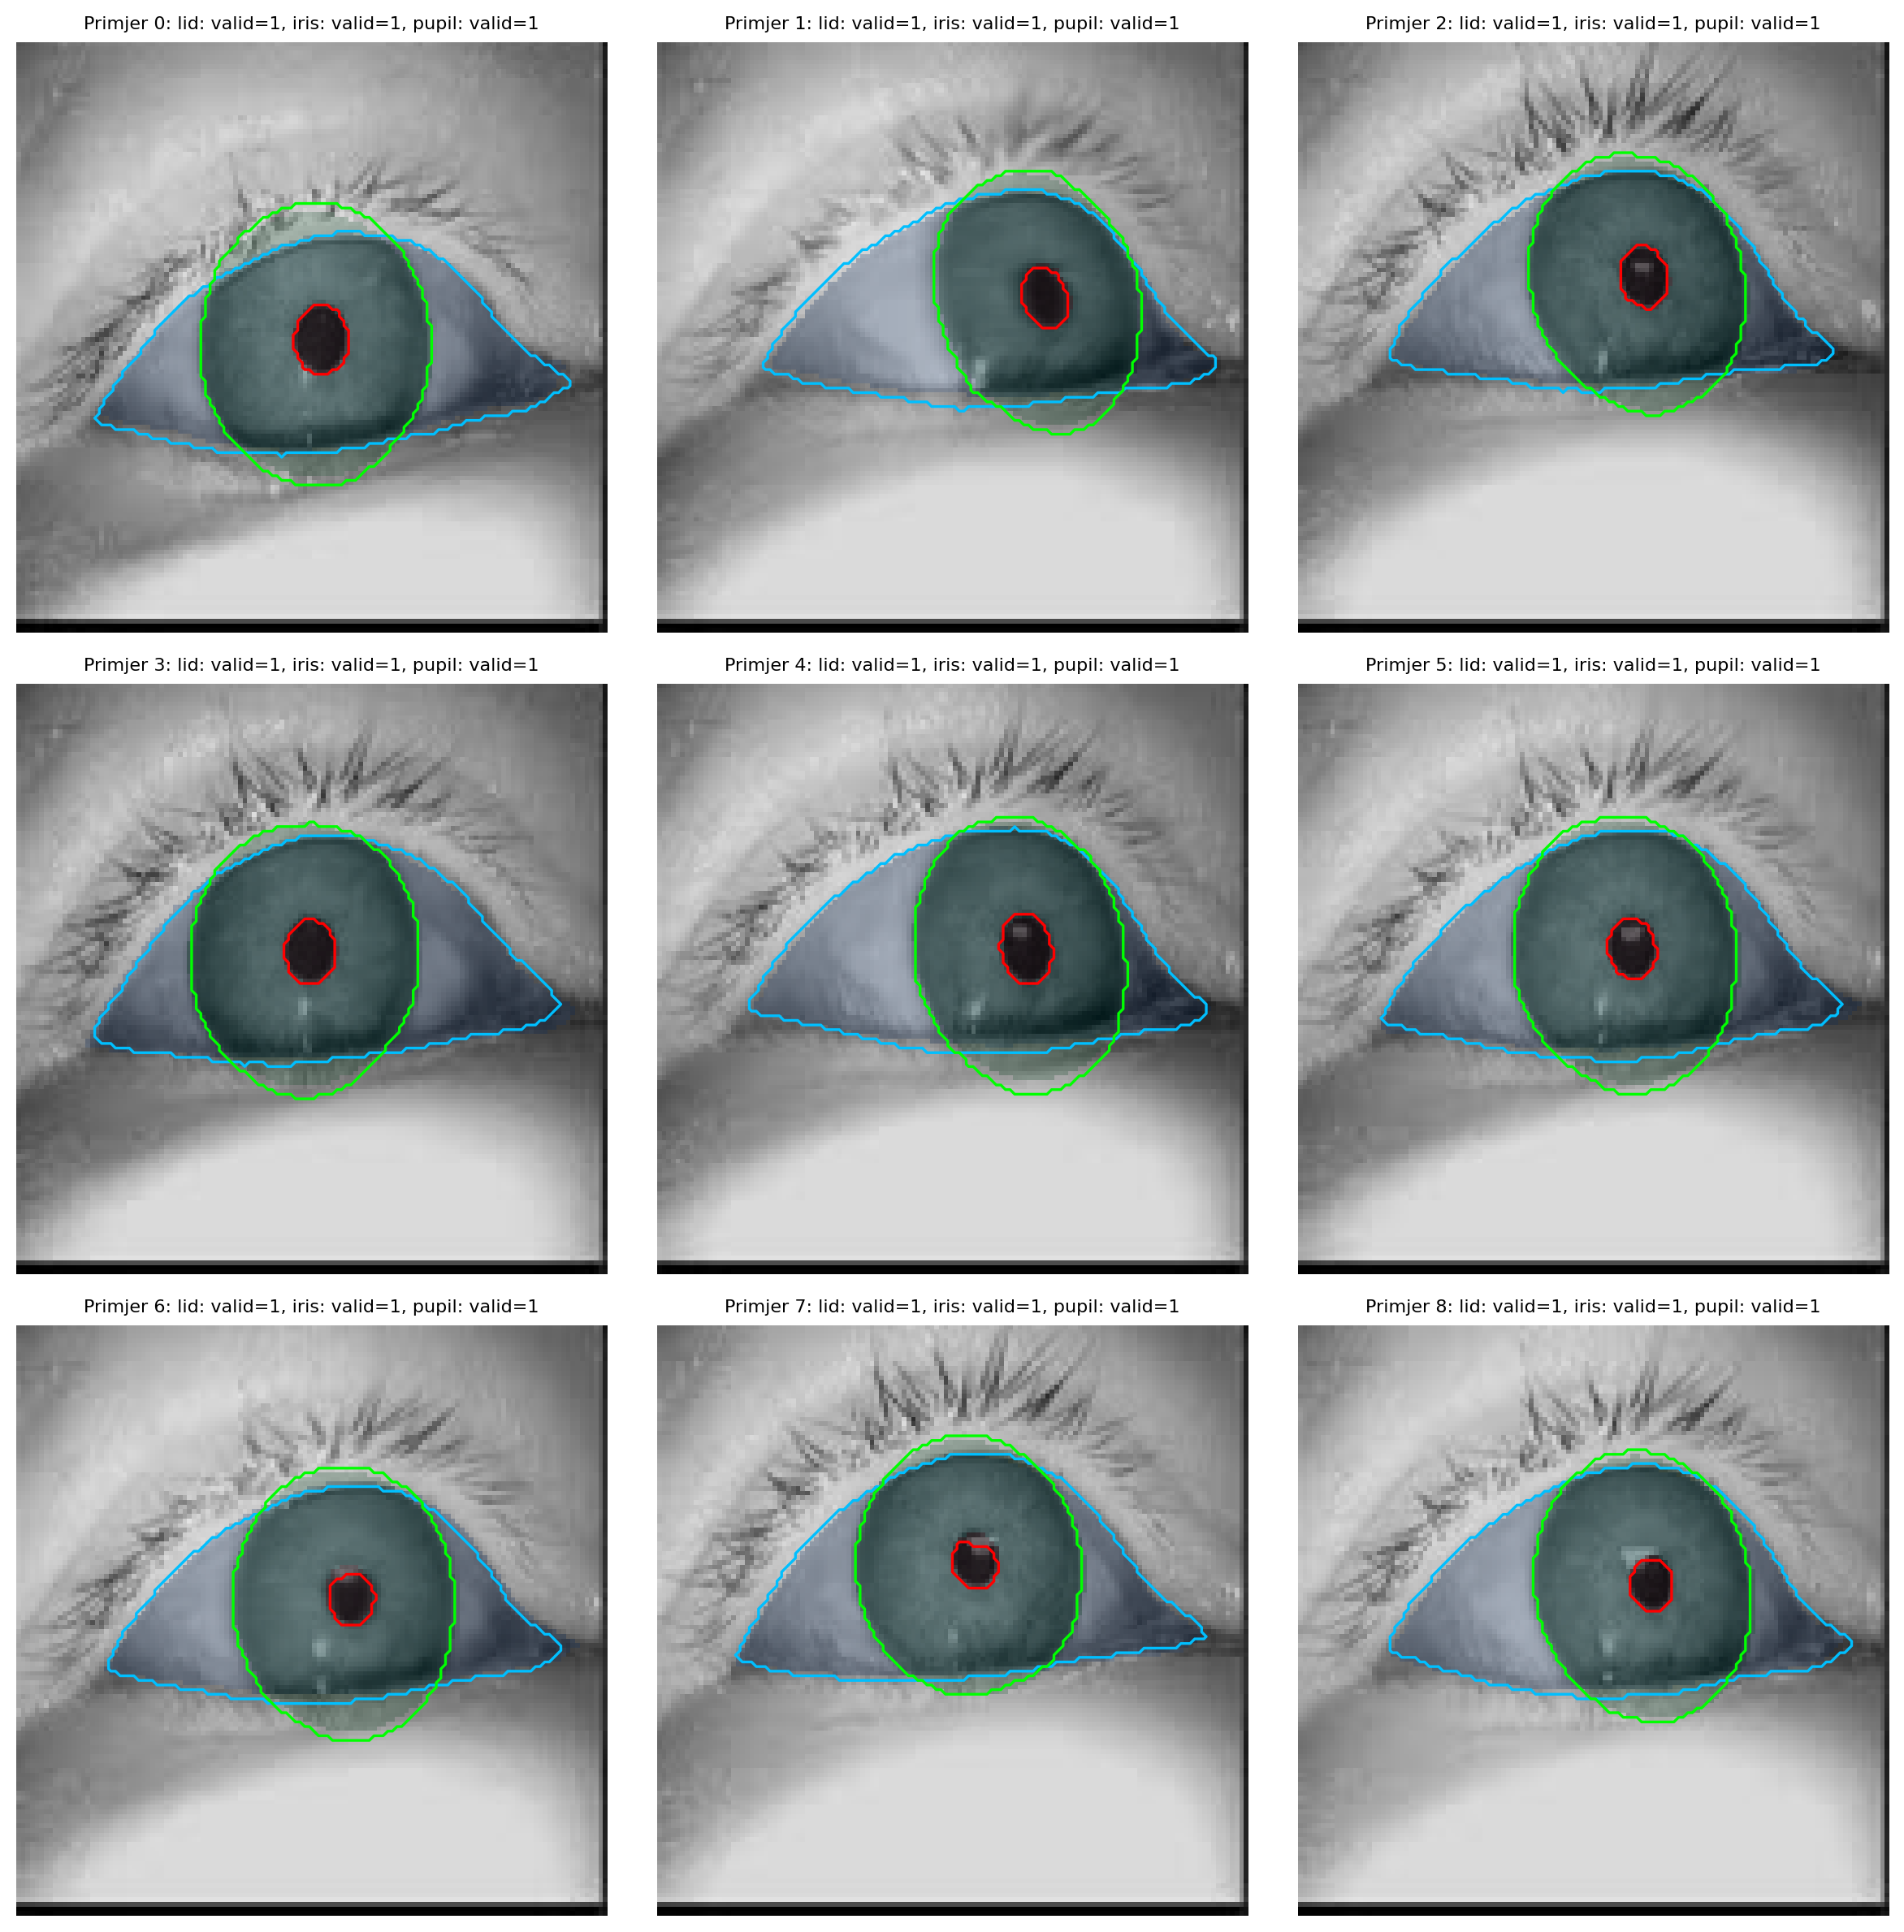

In [6]:
# Vizualizacije primjera predikcija za prvi uspješno učitani seed.
# Prikaz zadržava tri izlazna kanala bez obzira na aktivne loss kanale.
if seed_models:
    chosen_seed = next(iter(seed_models))
    output_dir = OUTPUT_BASE / f"seed_{chosen_seed}"
    model = keras.models.load_model(output_dir / "best_parts.keras", compile=False)
    sample_df = SPLIT_DF["val"].head(9)
    sample_ds = make_dataset(sample_df, SPLIT_ROOTS["val"], batch_size=min(9, len(sample_df)), training=False)
    sample_images, sample_targets = next(iter(sample_ds))
    sample_pred = model.predict(sample_images, verbose=0)

    def plot_segmentation_results(images, targets, predictions, output_dir, count=9, threshold=0.5):
        images = images.numpy() if hasattr(images, "numpy") else np.asarray(images)
        targets = targets.numpy() if hasattr(targets, "numpy") else np.asarray(targets)
        plt.figure(figsize=(12, 12), dpi=200)
        specs = [("lid", 2, "Blues", "deepskyblue"),
                 ("iris", 1, "Greens", "lime"),
                 ("pupil", 0, "Reds", "red")]
        for i in range(min(count, len(images))):
            plt.subplot(3, 3, i + 1)
            plt.imshow(np.clip(images[i] / 2.0 + 0.5, 0, 1))
            labels = []
            for part, ch, cmap, contour_color in specs:
                true_mask = targets[i, :, :, ch]
                pred_mask = predictions[i, :, :, ch]
                valid = targets[i, :, :, ch + 3] > 0.5
                true_bin = (true_mask >= 0.5) & valid
                pred_bin = (pred_mask >= threshold) & valid
                plt.imshow(true_bin.astype(float), cmap=cmap, alpha=true_bin.astype(float) * 0.22, vmin=0, vmax=1)
                if pred_bin.any() and not np.all(pred_bin):
                    plt.contour(pred_bin.astype(float), levels=[0.5], colors=[contour_color], linewidths=1.2)
                labels.append(f"{part}: valid={int(valid.any())}")
            plt.title(f"Primjer {i}: " + ", ".join(labels), fontsize=8)
            plt.axis("off")
        plt.tight_layout()
        plt.savefig(output_dir / "fig_parts_predictions.png", dpi=200, bbox_inches="tight")
        plt.show()

    plot_segmentation_results(sample_images, sample_targets, sample_pred, output_dir)
else:
    print("Nema uspješno treniranog/učitanog modela za vizualizaciju.")
